# ElasticNet Baseline: US and Canada

A concise workflow to build, evaluate and export independent US and CA reference-price models. Both countries use the supplied Top30 transaction snapshots. The output predicts recorded selling prices; it does not optimize prices or estimate causal elasticity.

## 1. Load Data

Read the supplied files without removing repeated transactions or changing their scope. Update `DATA_DIR` if needed. Dependencies: pandas 2.2.3, NumPy 1.26.4, SciPy 1.14.1, scikit-learn 1.7.2, matplotlib 3.10.9 and joblib 1.6.0. Models and tables are saved under `OUTPUT_DIR`.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib,json,platform,joblib,warnings,time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import scipy,sklearn
from IPython.display import display,Markdown
from sklearn.compose import ColumnTransformer,TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
COUNTRIES=['US','CA']
DATA_DIR=Path('/Users/AustinZhang/Desktop/Capstone/stage 1/pricing_eda_outputs')
OUTPUT_DIR=Path.cwd()/'elasticnet_artifacts'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
RANDOM_STATE=42
INNER_WEEKS=8
OUTER_WEEKS=13
OUTER_FOLDS=4
PARAMETER_GRID=[{'alpha':.001,'l1_ratio':.2},{'alpha':.01,'l1_ratio':.5},{'alpha':.1,'l1_ratio':.8}]
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
    'scipy':scipy.__version__,'scikit_learn':sklearn.__version__,'joblib':joblib.__version__}
pd.set_option('display.max_columns',25)
pd.set_option('display.max_rows',100)
pd.set_option('display.float_format',lambda x:f'{x:,.4f}')
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False})




In [ ]:
country_data = {}
source_metadata = {}
overview = []
for country in COUNTRIES:
    path = DATA_DIR / f"{country}_selected_top30_transactions.csv"
    df = pd.read_csv(
        path, low_memory=False, dtype={"product_id": str, "customer_id": str}
    )
    source_columns = list(df.columns)
    for col in ["pricing_date", "ship_date", "order_date"]:
        df[col] = pd.to_datetime(df[col], format="mixed", errors="raise")
    assert df.country.eq(country).all() and df.pricing_date.notna().all()
    assert df.order_units.gt(0).all() and df.revenue.gt(0).all()
    assert df.product_id.nunique() == 30
    assert df.groupby("product_id").product_name.nunique().max() == 1
    assert df.groupby("product_id").product_family.nunique().max() == 1
    assert np.isfinite(df[["revenue", "order_units"]].to_numpy()).all()
    df["unit_price"] = df.revenue / df.order_units
    country_data[country] = df
    source_metadata[country] = {
        "country": country,
        "source_file": str(path),
        "source_sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        "source_rows": len(df),
        "first_date": str(df.pricing_date.min().date()),
        "last_date": str(df.pricing_date.max().date()),
    }
    overview.append(
        {
            "country": country,
            "transaction_rows": len(df),
            "products": df.product_id.nunique(),
            "first_date": df.pricing_date.min().date(),
            "last_date": df.pricing_date.max().date(),
            "repeated_rows_retained": df[source_columns].duplicated().sum(),
        }
    )
display(pd.DataFrame(overview))

,country,transaction_rows,products,first_date,last_date,repeated_rows_retained
0,US,89086,30,2023-04-04,2026-08-29,6048
1,CA,17732,30,2023-06-14,2026-08-29,494


## 2. Build Features

Predict each product's daily ASP (`daily revenue / daily units`) using prior product/family prices, last price, historical sales activity and calendar information. Current-day revenue, ASP and price tier are excluded from predictors. Family history covers the supplied Top30 products only.

Use a 120-day warm-up. No-sale days provide the lag calendar but have no price label. The previous 90-day price window is [t−120,t−30). All rolling features exclude prediction day t. Supporting code is grouped below and collapsed where supported.

In [ ]:
def make_daily_panel(transactions, end_date=None):
    raw = transactions.copy()
    observed = raw.groupby(["product_id", "pricing_date"]).agg(
        revenue=("revenue", "sum"),
        units=("order_units", "sum"),
        transactions=("product_id", "size"),
        median_transaction_price=("unit_price", "median"),
    )
    meta = raw.groupby("product_id").agg(
        product_name=("product_name", "first"),
        product_family=("product_family", "first"),
        product_type=("product_type", "first"),
    )
    start = raw.pricing_date.min()
    end = (
        end_date
        if end_date is not None
        else raw.pricing_date.max() + pd.Timedelta(days=1)
    )
    grid = pd.MultiIndex.from_product(
        [sorted(meta.index), pd.date_range(start, end)],
        names=["product_id", "pricing_date"],
    )
    daily = (
        observed.reindex(grid)
        .reset_index()
        .merge(meta.reset_index(), on="product_id", validate="many_to_one")
    )
    for c in ["revenue", "units", "transactions"]:
        daily[c] = daily[c].fillna(0)
    daily["target_price"] = daily.revenue / daily.units.replace(0, np.nan)
    blocks = []
    for _, g in daily.groupby("product_id", sort=False):
        g = g.sort_values("pricing_date").copy()
        rev, units, tx = g.revenue.shift(1), g.units.shift(1), g.transactions.shift(1)
        for days in [7, 30, 90]:
            r = rev.rolling(days, min_periods=1).sum()
            u = units.rolling(days, min_periods=1).sum()
            g[f"price_{days}d"] = r / u.replace(0, np.nan)
            g[f"log_units_{days}d"] = np.log1p(u)
        g["transactions_30d"] = tx.rolling(30, min_periods=1).sum()
        g["price_previous_90d"] = g.revenue.shift(31).rolling(
            90, min_periods=1
        ).sum() / g.units.shift(31).rolling(90, min_periods=1).sum().replace(0, np.nan)
        g["last_price"] = g.target_price.ffill().shift(1)
        g["days_since_sale"] = (
            g.pricing_date - g.pricing_date.where(g.units.gt(0)).ffill().shift(1)
        ).dt.days
        g["active_days_30d"] = (
            g.units.gt(0).astype(float).shift(1).rolling(30, min_periods=1).sum()
        )
        blocks.append(g)
    daily = pd.concat(blocks, ignore_index=True)
    family = (
        daily.groupby(["product_family", "pricing_date"])[["revenue", "units"]]
        .sum()
        .reset_index()
    )
    family_blocks = []
    for _, g in family.groupby("product_family", sort=False):
        g = g.sort_values("pricing_date").copy()
        g["family_price_90d"] = g.revenue.shift(1).rolling(
            90, min_periods=1
        ).sum() / g.units.shift(1).rolling(90, min_periods=1).sum().replace(0, np.nan)
        family_blocks.append(g[["product_family", "pricing_date", "family_price_90d"]])
    daily = daily.merge(
        pd.concat(family_blocks),
        on=["product_family", "pricing_date"],
        validate="many_to_one",
    )
    country_daily = (
        daily.groupby("pricing_date")[["revenue", "units"]].sum().sort_index()
    )
    country_daily["past_country_price"] = country_daily.revenue.shift(
        1
    ).expanding().sum() / country_daily.units.shift(1).expanding().sum().replace(
        0, np.nan
    )
    daily = daily.merge(
        country_daily[["past_country_price"]], on="pricing_date", validate="many_to_one"
    )
    fallback = daily.family_price_90d.fillna(daily.past_country_price)
    for c in [
        "price_7d",
        "price_30d",
        "price_90d",
        "price_previous_90d",
        "last_price",
        "family_price_90d",
    ]:
        daily[c] = daily[c].fillna(fallback)
    daily["day_index"] = (daily.pricing_date - start).dt.days / 365.25
    daily["month"] = daily.pricing_date.dt.month.astype(str)
    daily["weekday"] = daily.pricing_date.dt.dayofweek.astype(str)
    daily["sin_year"] = np.sin(2 * np.pi * daily.pricing_date.dt.dayofyear / 365.25)
    daily["cos_year"] = np.cos(2 * np.pi * daily.pricing_date.dt.dayofyear / 365.25)
    return daily.sort_values(["pricing_date", "product_id"]).reset_index(drop=True)


price_numeric = [
    "price_7d",
    "price_30d",
    "price_90d",
    "price_previous_90d",
    "family_price_90d",
    "last_price",
    "days_since_sale",
    "active_days_30d",
    "log_units_7d",
    "log_units_30d",
    "log_units_90d",
    "transactions_30d",
    "day_index",
    "sin_year",
    "cos_year",
]
price_categorical = ["product_id", "product_family", "product_type", "month", "weekday"]
price_features = price_numeric + price_categorical
blend_features = ["price_30d", "family_price_90d", "price_previous_90d"]

In [ ]:
panels = {}
country_splits = {}
split_rows = []
for country, df in country_data.items():
    panel = make_daily_panel(df)
    last_date = df.pricing_date.max()
    week_start = last_date - pd.Timedelta(days=last_date.dayofweek)
    complete_week = (
        week_start if last_date.dayofweek == 6 else week_start - pd.Timedelta(weeks=1)
    )
    backtest_end = complete_week + pd.Timedelta(weeks=1)
    warmup_end = df.pricing_date.min() + pd.Timedelta(days=120)
    panels[country] = panel
    folds = []
    for fold in range(OUTER_FOLDS):
        end = backtest_end - pd.Timedelta(weeks=OUTER_WEEKS * (OUTER_FOLDS - 1 - fold))
        start = end - pd.Timedelta(weeks=OUTER_WEEKS)
        folds.append((start, end))
        split_rows.append(
            {
                "country": country,
                "fold": fold + 1,
                "inner_validation_start": start - pd.Timedelta(weeks=INNER_WEEKS),
                "outer_start": start,
                "outer_end_exclusive": end,
            }
        )
    country_splits[country] = {
        "last_date": last_date,
        "warmup_end": warmup_end,
        "backtest_end": backtest_end,
        "folds": folds,
    }
    # Future records must not change a historical feature vector.
    checkpoint = (
        df.pricing_date.min() + (last_date - df.pricing_date.min()) / 2
    ).normalize()
    prefix = make_daily_panel(df[df.pricing_date.le(checkpoint)], end_date=checkpoint)
    a = panel[panel.pricing_date.eq(checkpoint)].set_index("product_id")
    b = prefix[prefix.pricing_date.eq(checkpoint)].set_index("product_id")
    pd.testing.assert_frame_equal(a.loc[b.index, price_numeric], b[price_numeric])

## 3. Evaluate ElasticNet

Use four expanding 13-week historical backtests. For each period, tune the declared ElasticNet grid on the preceding 8-week validation window, then refit on all earlier labels. Evaluate rolling one-day-ahead predictions against the original 50/30/20 formula on identical product-days. Lower WAPE, MAE and RMSE are better; higher R² is better.

These dates were previously reviewed, so results are exploratory backtests, not a fresh independent test. Completed previous days may update lag features; model parameters stay fixed within each outer period. Prefix checks verify that future rows cannot change past features.

In [ ]:
def build_elasticnet(params):
    prep = ColumnTransformer(
        [
            (
                "num",
                Pipeline(
                    [
                        (
                            "impute",
                            SimpleImputer(strategy="median", keep_empty_features=True),
                        ),
                        ("scale", StandardScaler()),
                    ]
                ),
                price_numeric,
            ),
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                price_categorical,
            ),
        ],
        remainder="drop",
    )
    estimator = TransformedTargetRegressor(
        regressor=ElasticNet(
            alpha=params["alpha"],
            l1_ratio=params["l1_ratio"],
            max_iter=20000,
            tol=1e-5,
            random_state=RANDOM_STATE,
        ),
        transformer=StandardScaler(),
    )
    return Pipeline([("prep", prep), ("model", estimator)])


def fit_elasticnet(params, data):
    model = build_elasticnet(params)
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        model.fit(data[price_features], data.target_price)
    return model


def predict_reference(model, data):
    p = np.maximum(model.predict(data[price_features]), 0.01)
    assert np.isfinite(p).all()
    return p


def metrics(y, p, ids):
    y, p = np.asarray(y), np.asarray(p)
    grouped = (
        pd.DataFrame({"id": np.asarray(ids), "ae": abs(y - p), "actual": y})
        .groupby("id")[["ae", "actual"]]
        .sum()
    )
    return {
        "MAE": mean_absolute_error(y, p),
        "RMSE": mean_squared_error(y, p) ** 0.5,
        "WAPE_pct": 100 * abs(y - p).sum() / y.sum(),
        "R2": r2_score(y, p),
        "macro_product_WAPE_pct": (100 * grouped.ae / grouped.actual).mean(),
    }


def choose_parameters(early, late):
    candidates = []
    for params in PARAMETER_GRID:
        model = fit_elasticnet(params, early)
        score = metrics(
            late.target_price, predict_reference(model, late), late.product_id
        )["WAPE_pct"]
        candidates.append({**params, "inner_WAPE_pct": score})
    table = (
        pd.DataFrame(candidates).sort_values("inner_WAPE_pct").reset_index(drop=True)
    )
    return {
        "alpha": float(table.iloc[0].alpha),
        "l1_ratio": float(table.iloc[0].l1_ratio),
    }, table


def coefficient_table(model):
    transformer = model.named_steps["prep"]
    target = model.named_steps["model"]
    estimator = target.regressor_
    feature_names = transformer.get_feature_names_out()
    beta = np.asarray(estimator.coef_)
    y_scale = float(target.transformer_.scale_[0])
    y_mean = float(target.transformer_.mean_[0])
    scale = transformer.named_transformers_["num"].named_steps["scale"]
    n = len(price_numeric)
    raw_beta = beta * y_scale
    raw_beta[:n] = raw_beta[:n] / scale.scale_
    raw_intercept = (
        y_mean
        + y_scale * float(estimator.intercept_)
        - float(np.sum(raw_beta[:n] * scale.mean_))
    )
    table = pd.DataFrame(
        {
            "feature": feature_names,
            "feature_type": ["numeric"] * n + ["one_hot"] * (len(feature_names) - n),
            "coefficient_standardized_target": beta,
            "price_change_per_transformed_feature_unit": beta * y_scale,
            "coefficient_original_units": raw_beta,
            "zeroed_by_L1": np.isclose(beta, 0, atol=1e-10),
        }
    )
    table["absolute_standardized_coefficient"] = (
        table.coefficient_standardized_target.abs()
    )
    info = {
        "intercept_standardized_target": float(estimator.intercept_),
        "intercept_original_units": raw_intercept,
        "target_mean": y_mean,
        "target_scale": y_scale,
        "numeric_training_means": dict(zip(price_numeric, map(float, scale.mean_))),
        "numeric_training_scales": dict(zip(price_numeric, map(float, scale.scale_))),
        "n_iter": int(estimator.n_iter_),
        "dual_gap": float(estimator.dual_gap_),
    }
    return table, info


def evaluate_country(country, panel, settings):
    data = panel[
        panel.units.gt(0)
        & panel.pricing_date.ge(settings["warmup_end"])
        & panel.pricing_date.lt(settings["backtest_end"])
    ]
    rows = []
    predictions = []
    for fold, (start, end) in enumerate(settings["folds"], 1):
        train = data[data.pricing_date.lt(start)]
        outer = data[data.pricing_date.ge(start) & data.pricing_date.lt(end)]
        inner_start = start - pd.Timedelta(weeks=INNER_WEEKS)
        early = train[train.pricing_date.lt(inner_start)]
        late = train[train.pricing_date.ge(inner_start)]
        assert early.pricing_date.max() < late.pricing_date.min()
        assert train.pricing_date.max() < outer.pricing_date.min()
        params, _ = choose_parameters(early, late)
        fitted = fit_elasticnet(params, train)
        forecasts = {
            "ElasticNet": predict_reference(fitted, outer),
            "Original formula": np.maximum(
                (outer[blend_features].to_numpy() * np.array([0.5, 0.3, 0.2])).sum(
                    axis=1
                ),
                0.01,
            ),
        }
        for name, pred in forecasts.items():
            rows.append(
                {
                    "country": country,
                    "fold": fold,
                    "model": name,
                    **metrics(outer.target_price, pred, outer.product_id),
                }
            )
            record = outer[
                ["product_id", "product_name", "pricing_date", "target_price"]
            ].copy()
            record["country"] = country
            record["model"] = name
            record["prediction"] = pred
            record["absolute_error"] = abs(record.target_price - record.prediction)
            predictions.append(record)
    return pd.DataFrame(rows), pd.concat(predictions, ignore_index=True)

In [ ]:
evaluations = [evaluate_country(c, panels[c], country_splits[c]) for c in COUNTRIES]
fold_results = pd.concat([x[0] for x in evaluations], ignore_index=True)
historical_predictions = pd.concat([x[1] for x in evaluations], ignore_index=True)
assert len(fold_results) == len(COUNTRIES) * OUTER_FOLDS * 2
assert not historical_predictions.duplicated(
    ["country", "model", "product_id", "pricing_date"]
).any()
performance = (
    fold_results.groupby(["country", "model"])
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_WAPE_pct=("WAPE_pct", "max"),
        MAE=("MAE", "mean"),
        RMSE=("RMSE", "mean"),
        R2=("R2", "mean"),
    )
    .reset_index()
)
display(performance)

,country,model,mean_WAPE_pct,worst_WAPE_pct,MAE,RMSE,R2
0,CA,ElasticNet,11.9012,12.7920,151.0705,253.1908,0.8230
1,CA,Original formula,12.8574,13.3829,163.2056,267.9773,0.8030
2,US,ElasticNet,10.8315,12.5191,130.7055,257.8868,0.8793
3,US,Original formula,13.1326,15.5747,158.0293,296.7320,0.8387


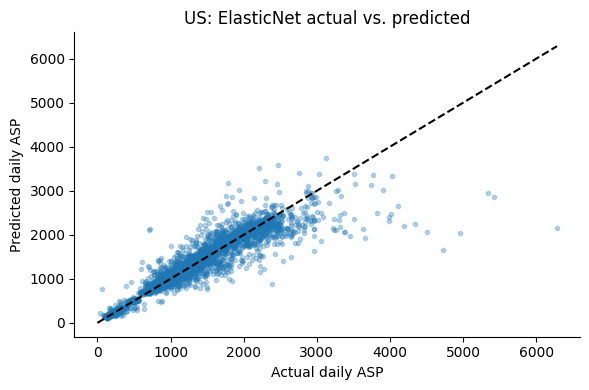

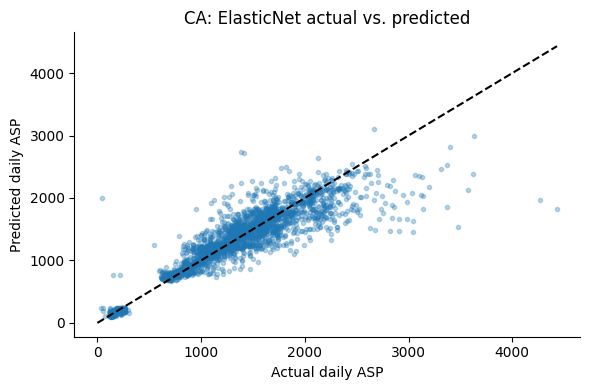

,country,product_name,product_days,WAPE_pct
0,US,INSIGHTRPVL XR X4 ZONE JET 8(NUOE) V,131,22.8419
1,US,CYPRESSIOFW SC K3_MDMJD_VPB 0_E942_OF_B,166,22.4437
2,US,MONARCH DE E47W WAY 3_U536_ZEOL_BR_U,130,17.0746
3,US,58OUYK5D87 SIGNAL WAY,63,16.9325
4,US,CENTURY RA O66A JET 2 J5E5594RA 01E 445X,141,15.9886
5,CA,CYPRESSIOFW SC K3_MDMJD_VPB 0_E942_OF_B,82,27.2365
6,CA,INSIGHTRPVL XR X4 ZONE JET 8(NUOE) V,79,20.4733
7,CA,A61L(P88238IC4)21MAWP OGEEJQU(CEQV N),116,18.3582
8,CA,CATALYST MOMENTUM P01P JET 1 WAY JET 55Q,89,17.7787
9,CA,EMBERFCKGPT X82,134,16.4714


In [ ]:
elastic_predictions = historical_predictions[
    historical_predictions.model.eq("ElasticNet")
]
product_errors = elastic_predictions.groupby(
    ["country", "product_id", "product_name"]
).agg(
    product_days=("target_price", "size"),
    absolute_error=("absolute_error", "sum"),
    actual_price_sum=("target_price", "sum"),
)
product_errors["WAPE_pct"] = (
    100 * product_errors.absolute_error / product_errors.actual_price_sum
)
for country in COUNTRIES:
    observed = elastic_predictions[elastic_predictions.country.eq(country)]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(observed.target_price, observed.prediction, s=9, alpha=0.3)
    upper = max(observed.target_price.max(), observed.prediction.max())
    ax.plot([0, upper], [0, upper], "k--")
    ax.set(
        title=f"{country}: ElasticNet actual vs. predicted",
        xlabel="Actual daily ASP",
        ylabel="Predicted daily ASP",
    )
    fig.tight_layout()
    fig.canvas.draw()
    display(fig)
    plt.close(fig)
worst_products = pd.concat(
    [
        product_errors.loc[c]
        .sort_values("WAPE_pct", ascending=False)
        .head(5)
        .assign(country=c)
        for c in COUNTRIES
    ]
)
display(
    worst_products.reset_index()[
        ["country", "product_name", "product_days", "WAPE_pct"]
    ]
)

## 4. Train Final Models and Show Coefficients

For each country, choose parameters on the latest available 8-week window, then refit using all labeled history after warm-up. The performance table above evaluates this fitting procedure; it is not an in-sample score for the final refit.

Show the final intercept and nonzero coefficients in original units. Numeric coefficients refer to one raw feature unit after imputation; categorical terms are one-hot contributions. Full one-hot encoding and correlated predictors limit individual interpretation. These coefficients are not causal effects or elasticities, and their magnitudes across different units are not directly comparable. Full coefficient tables, including zeros, are exported.

In [ ]:
def train_final_country(country, panel, settings):
    train = panel[
        panel.units.gt(0)
        & panel.pricing_date.ge(settings["warmup_end"])
        & panel.pricing_date.le(settings["last_date"])
    ].copy()
    cutoff = settings["last_date"] - pd.Timedelta(weeks=INNER_WEEKS)
    early = train[train.pricing_date.lt(cutoff)]
    late = train[train.pricing_date.ge(cutoff)]
    params, _ = choose_parameters(early, late)
    fitted = fit_elasticnet(params, train)
    coefficients, coefficient_info = coefficient_table(fitted)
    # Verify the original-unit formula, without printing the intermediate calculations.
    probe = train.sample(n=min(100, len(train)), random_state=RANDOM_STATE)
    design = np.asarray(
        fitted.named_steps["prep"].transform(probe[price_features])
    ).copy()
    scale = fitted.named_steps["prep"].named_transformers_["num"].named_steps["scale"]
    design[:, : len(price_numeric)] = (
        design[:, : len(price_numeric)] * scale.scale_ + scale.mean_
    )
    manual = coefficient_info["intercept_original_units"] + (
        design * coefficients.coefficient_original_units.to_numpy()
    ).sum(axis=1)
    np.testing.assert_allclose(
        manual, fitted.predict(probe[price_features]), rtol=1e-8, atol=1e-7
    )
    return {
        "model": fitted,
        "parameters": params,
        "coefficients": coefficients,
        "coefficient_info": coefficient_info,
        "training_product_days": len(train),
    }

In [ ]:
final_models = {
    c: train_final_country(c, panels[c], country_splits[c]) for c in COUNTRIES
}
model_summary = pd.DataFrame(
    [
        {
            "country": c,
            **result["parameters"],
            "training_product_days": result["training_product_days"],
            "intercept_original_units": result["coefficient_info"][
                "intercept_original_units"
            ],
        }
        for c, result in final_models.items()
    ]
)
display(model_summary)
nonzero_coefficients = pd.concat(
    [result["coefficients"].assign(country=c) for c, result in final_models.items()],
    ignore_index=True,
)
nonzero_coefficients = nonzero_coefficients[~nonzero_coefficients.zeroed_by_L1]
display(
    nonzero_coefficients[
        ["country", "feature", "coefficient_original_units"]
    ].reset_index(drop=True)
)

,country,alpha,l1_ratio,training_product_days,intercept_original_units
0,US,0.0100,0.5000,9484,1.4181
1,CA,0.0100,0.5000,4707,-21.4166


,country,feature,coefficient_original_units
0,US,num__price_7d,0.2100
1,US,num__price_30d,0.2645
2,US,num__price_90d,0.1332
3,US,num__price_previous_90d,0.0941
4,US,num__family_price_90d,0.0023
5,US,num__last_price,0.2949
6,US,num__days_since_sale,1.0852
7,US,num__active_days_30d,-0.5469
8,US,num__day_index,9.8586
9,US,cat__product_family_Product Family Solar Peak,9.4204


## 5. Export Models

Save separate fitted US and CA `.joblib` bundles, full coefficient tables, the performance/parameter summaries and complete per-product error tables. Keep reload and coefficient checks automatic rather than printing their intermediate calculations.

Saved pipelines include imputation, scaling, encoding, ElasticNet and inverse target scaling. To reuse a model, rebuild features with `make_daily_panel()`, pass the saved `feature_columns` to `bundle['model'].predict(...)`, and floor predictions at the saved `prediction_floor_recorded_units`. Raw transaction CSV rows cannot be passed directly to the fitted pipeline. Use later data for the next independent performance check.

In [ ]:
def export_country_model(country, result):
    metadata = {
        **source_metadata[country],
        "parameters": result["parameters"],
        "versions": VERSIONS,
        "feature_engineering_version": "daily_prior_only_v1",
        "feature_columns": price_features,
        "numeric_features": price_numeric,
        "categorical_features": price_categorical,
        "prediction_floor_recorded_units": 0.01,
        "warmup_days": 120,
        "input_contract": "Engineered product-day features from this notebook; not raw transaction rows",
        "target": "Daily revenue / daily units in original recorded units",
        "coefficient_information": result["coefficient_info"],
        "training_product_days": result["training_product_days"],
        "product_name_lookup": country_data[country]
        .groupby("product_id")
        .product_name.first()
        .to_dict(),
        "performance_note": "Previously inspected historical backtests; not a new independent test",
    }
    bundle = {
        "model": result["model"],
        "metadata": metadata,
        "feature_columns": price_features,
    }
    path = OUTPUT_DIR / f"{country}_elasticnet_baseline.joblib"
    joblib.dump(bundle, path, compress=3)
    result["coefficients"].to_csv(
        OUTPUT_DIR / f"{country}_coefficients.csv", index=False
    )
    product_errors.loc[country].reset_index().to_csv(
        OUTPUT_DIR / f"{country}_product_errors.csv", index=False
    )
    reloaded = joblib.load(path)
    check_rows = panels[country][
        panels[country].pricing_date.eq(
            country_splits[country]["last_date"] + pd.Timedelta(days=1)
        )
    ]
    np.testing.assert_allclose(
        predict_reference(result["model"], check_rows),
        np.maximum(
            reloaded["model"].predict(check_rows[reloaded["feature_columns"]]), 0.01
        ),
        rtol=1e-12,
        atol=1e-12,
    )
    return {
        "country": country,
        "model_file": path.name,
        "coefficient_file": f"{country}_coefficients.csv",
    }

In [ ]:
exported = pd.DataFrame([export_country_model(c, final_models[c]) for c in COUNTRIES])
performance.to_csv(OUTPUT_DIR / "performance.csv", index=False)
model_summary.to_csv(OUTPUT_DIR / "model_summary.csv", index=False)
assert all(len(country_data[c]) == source_metadata[c]["source_rows"] for c in COUNTRIES)
display(exported)
print(
    "US and CA models exported. Coefficient reconstruction and saved-model reload checks passed."
)
print("Saved to:", OUTPUT_DIR.resolve())

,country,model_file,coefficient_file
0,US,US_elasticnet_baseline.joblib,US_coefficients.csv
1,CA,CA_elasticnet_baseline.joblib,CA_coefficients.csv


US and CA models exported. Coefficient reconstruction and saved-model reload checks passed.
Saved to: /Users/AustinZhang/Desktop/Capstone/elasticnet_artifacts
